In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


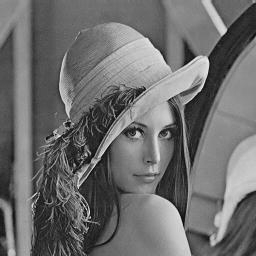

In [2]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gimg = cv2.cvtColor(RGB_img, cv2.COLOR_BGR2GRAY)
print(gimg.shape)
cv2_imshow(gimg)

In [5]:
height, width = gimg.shape
print(height, width)

256 256


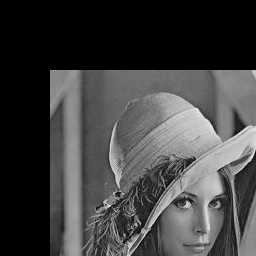

In [6]:
T = np.float32([[1,0,50],[0,1,70]])
outimg = cv2.warpAffine(gimg, T, (width, height))
cv2_imshow(outimg)

[[  0.76604444   0.64278761 -52.33050276]
 [ -0.64278761   0.76604444 112.22312532]]


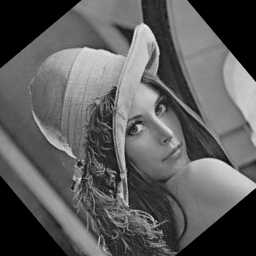

In [20]:
R = cv2.getRotationMatrix2D((width/2, height/2), 40, 1)
print(R)
outimg = cv2.warpAffine(gimg, R, (width, height))
cv2_imshow(outimg)

[[ 0.76604444  0.64278761  0.        ]
 [-0.64278761  0.76604444  0.        ]]


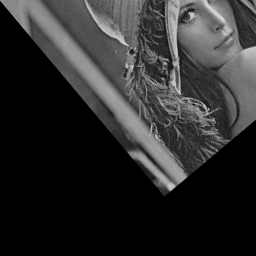

In [21]:
R = cv2.getRotationMatrix2D((0,0), 40, 1)
print(R)
outimg = cv2.warpAffine(gimg, R, (width, height))
cv2_imshow(outimg)

[[ 0.76604444  0.64278761  0.        ]
 [-0.64278761  0.76604444  0.        ]]


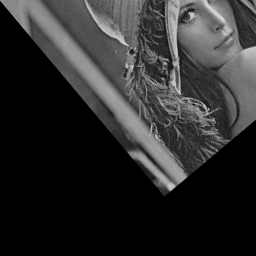

In [22]:
R = cv2.getRotationMatrix2D((0,0), 40, 1)
print(R)
outimg = cv2.warpAffine(gimg, R, (width, height))
cv2_imshow(outimg)

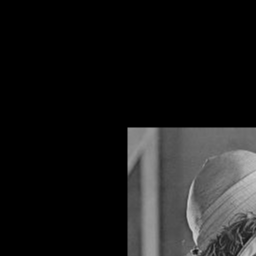

In [23]:
T2 = np.float32([[1,0,(width-1)/2],[0,1,(height-1)/2]])
outimg2 = cv2.warpAffine(gimg, T2, (width, height))
cv2_imshow(outimg2)

[[  0.76604444   0.64278764 -52.1261    ]
 [ -0.64278764   0.76604444 111.78476   ]
 [  0.           0.           1.        ]]


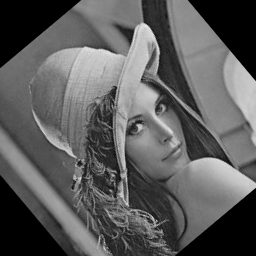

In [28]:
T1 = np.float32([[1,0,-(width-1)/2],[0,1,-(height-1)/2],[0,0,1]])
R = cv2.getRotationMatrix2D((0,0), 40, 1)
R1 = np.float32([[R[0,0], R[0,1], R[0,2]],[R[1,0],R[1,1], R[1,2]],[0,0,1]])
T2 = np.float32([[1,0,(width-1)/2],[0,1,(height-1)/2],[0,0,1]])

M1 = np.dot(R1, T1)
M2 = np.dot(T2, M1)
print(M2)
M = np.float32([[M2[0,0],M2[0,1], M2[0,2]],[M2[1,0],M2[1,1],M2[1,2]]])
outimg = cv2.warpAffine(gimg, M, (width, height))
cv2_imshow(outimg)